In [ ]:

!pip install mlflow

In [ ]:
#creating baseline model
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv('/content/reviews_sentiment.csv')
df.head()

,review,label
0,"the ambience was good, food was quite good . h...",positive
1,ambience is too good for a pleasant evening. s...,positive
2,a must try.. great food great ambience. thnx f...,positive
3,soumen das and arun was a great guy. only beca...,positive
4,food is good.we ordered kodi drumsticks and ba...,positive


In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [ ]:
# Ensure necessary NLTK data is downloaded
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
# Define the preprocessing function
def preprocess_comment(comment):
    # Convert to lowercase
    comment = comment.lower()

    # Remove trailing and leading whitespaces
    comment = comment.strip()

    # Remove newline characters
    comment = re.sub(r'\n', ' ', comment)

    # Remove non-alphanumeric characters, except punctuation
    comment = re.sub(r'[^A-Za-z0-9\s!?.,]', '', comment)

    # Remove stopwords but retain important ones for sentiment analysis
    stop_words = set(stopwords.words('english')) - {'not', 'but', 'however', 'no', 'yet'}
    comment = ' '.join([word for word in comment.split() if word not in stop_words])

    # Lemmatize the words
    lemmatizer = WordNetLemmatizer()
    comment = ' '.join([lemmatizer.lemmatize(word) for word in comment.split()])

    return comment

In [ ]:
# Apply the preprocessing function to the 'clean_comment' column
df['review'] = df['review'].apply(preprocess_comment)

In [ ]:
df.head()

,review,label
0,"ambience good, food quite good . saturday lunc...",positive
1,ambience good pleasant evening. service prompt...,positive
2,must try.. great food great ambience. thnx ser...,positive
3,"soumen da arun great guy. behavior sincerety, ...",positive
4,food good.we ordered kodi drumstick basket mut...,positive


In [ ]:
import mlflow
import mlflow.sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Step 1: Vectorize the comments using Bag of Words (CountVectorizer)
vectorizer = CountVectorizer(max_features=10000)  # Bag of Words model with a limit of 1000 features

In [ ]:
X = vectorizer.fit_transform(df['review']).toarray()
y = df['label']  # Assuming 'sentiment' is the target variable (0 or 1 for binary classification)

In [ ]:
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [ ]:
X.shape

(9954, 10000)

In [ ]:
y

,label
0,positive
1,positive
2,positive
3,positive
4,positive
...,...
9949,negative
9950,positive
9951,negative
9952,positive


In [ ]:
y.shape

(9954,)

In [ ]:
!aws configure

AWS Access Key ID [None]: 
AWS Secret Access Key [None]: 
Default region name [None]: ap-southeast-1
Default output format [None]: 


In [ ]:
# Step 2: Set up the MLflow tracking server
mlflow.set_tracking_uri("http://ec2-54-179-95-179.ap-southeast-1.compute.amazonaws.com:5000/")

In [ ]:
!pip install boto3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 63.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 7.9 MB/s eta 0:00:00


In [ ]:
!pip install awscli

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.2/20.2 MB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 570.5/570.5 kB 23.3 MB/s eta 0:00:00
  Attempting uninstall: rsa
    Found existing installation: rsa 4.9.1
    Uninstalling rsa-4.9.1:
      Successfully uninstalled rsa-4.9.1
  Attempting uninstall: docutils
    Found existing installation: docutils 0.21.2
    Uninstalling docutils-0.21.2:
      Successfully uninstalled docutils-0.21.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.


In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
from sklearn.metrics import confusion_matrix

In [ ]:
import mlflow

TRACKING_URI = "http://ec2-54-179-95-179.ap-southeast-1.compute.amazonaws.com:5000"

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment("Shopee_Sentiment_ArtifactProxy_v2")

exp = mlflow.get_experiment_by_name("Shopee_Sentiment_ArtifactProxy_v2")
print("Experiment:", exp.name)
print("Artifact location:", exp.artifact_location)


Experiment: Shopee_Sentiment_ArtifactProxy_v2
Artifact location: mlflow-artifacts:/3


🏃 View run RandomForest_Baseline_TrainTestSplit at: http://ec2-54-179-95-179.ap-southeast-1.compute.amazonaws.com:5000/#/experiments/3/runs/56153e9100af45548609db3463b75955
🧪 View experiment at: http://ec2-54-179-95-179.ap-southeast-1.compute.amazonaws.com:5000/#/experiments/3
Accuracy: 0.7674535409342039


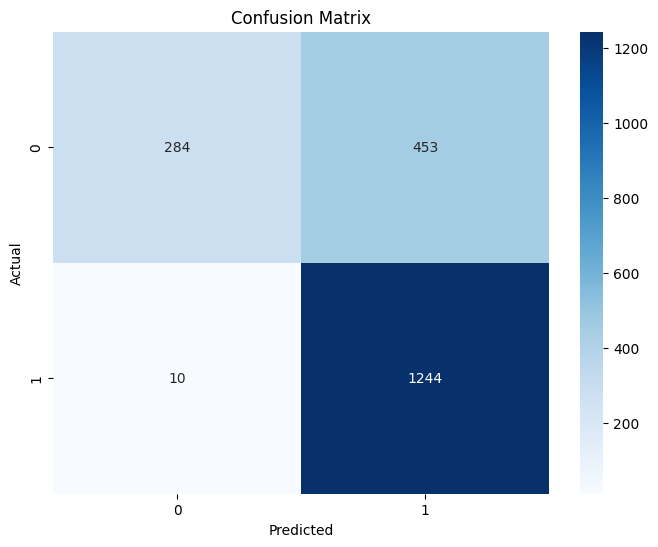

In [ ]:
# Step 1: Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Step 2: Define and train a Random Forest baseline model using a simple train-test split
with mlflow.start_run() as run:
    # Log a description for the run
    mlflow.set_tag("mlflow.runName", "RandomForest_Baseline_TrainTestSplit")
    mlflow.set_tag("experiment_type", "baseline")
    mlflow.set_tag("model_type", "RandomForestClassifier")

    # Add a description
    mlflow.set_tag("description", "Baseline RandomForest model for sentiment analysis using Bag of Words (BoW) with a simple train-test split")

    # Log parameters for the vectorizer
    mlflow.log_param("vectorizer_type", "CountVectorizer")
    mlflow.log_param("vectorizer_max_features", vectorizer.max_features)

    # Log Random Forest parameters
    n_estimators = 200
    max_depth = 15

    mlflow.log_param("n_estimators", n_estimators)
    mlflow.log_param("max_depth", max_depth)

    # Initialize and train the model
    model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=42)
    model.fit(X_train, y_train)

    # Make predictions on the test set
    y_pred = model.predict(X_test)

    # Log metrics for each class and accuracy
    accuracy = accuracy_score(y_test, y_pred)
    mlflow.log_metric("accuracy", accuracy)

    classification_rep = classification_report(y_test, y_pred, output_dict=True)

    for label, metrics in classification_rep.items():
        if isinstance(metrics, dict):  # For precision, recall, f1-score, etc.
            for metric, value in metrics.items():
                mlflow.log_metric(f"{label}_{metric}", value)

    # Confusion matrix plot
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Confusion Matrix")

    # Save and log the confusion matrix plot
    plt.savefig("confusion_matrix.png")
    mlflow.log_artifact("/content/confusion_matrix.png")

    mlflow.sklearn.log_model(
    sk_model=model,
    name="random_forest_model",
    skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

    # Optionally log the dataset itself (if it's small enough)
    df.to_csv("dataset.csv", index=False)
    mlflow.log_artifact("/content/dataset.csv")

# Display final accuracy
print(f"Accuracy: {accuracy}")

In [ ]:
import mlflow

TRACKING_URI = (
    "http://ec2-54-179-95-179.ap-southeast-1.compute.amazonaws.com:5000"
)

mlflow.set_tracking_uri(TRACKING_URI)

print("Tracking URI:", mlflow.get_tracking_uri())

for exp_id in ["0", "3"]:
    exp = mlflow.get_experiment(exp_id)
    print(
        f"Experiment {exp_id}:",
        exp.name,
        "| Artifact location:",
        exp.artifact_location
    )


Tracking URI: http://ec2-54-179-95-179.ap-southeast-1.compute.amazonaws.com:5000
Experiment 0: Default | Artifact location: s3://mlflow-shoppe-s3/0
Experiment 3: Shopee_Sentiment_ArtifactProxy_v2 | Artifact location: mlflow-artifacts:/3


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.97      0.39      0.55       737
    positive       0.73      0.99      0.84      1254

    accuracy                           0.77      1991
   macro avg       0.85      0.69      0.70      1991
weighted avg       0.82      0.77      0.73      1991



In [ ]:
df.to_csv("/content/data_prerpocessing.csv", index=False, encoding="utf-8-sig")

In [ ]:
df.head()

,review,label
0,"ambience good, food quite good . saturday lunc...",positive
1,ambience good pleasant evening. service prompt...,positive
2,must try.. great food great ambience. thnx ser...,positive
3,"soumen da arun great guy. behavior sincerety, ...",positive
4,food good.we ordered kodi drumstick basket mut...,positive


In [ ]:
# Step 1: Function to run the experiment
def run_experiment(vectorizer_type, ngram_range, vectorizer_max_features, vectorizer_name):
    # Step 2: Vectorization
    if vectorizer_type == "BoW":
        vectorizer = CountVectorizer(ngram_range=ngram_range, max_features=vectorizer_max_features)
    else:
        vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=vectorizer_max_features)

    X_train, X_test, y_train, y_test = train_test_split(df['review'], df['label'], test_size=0.2, random_state=42, stratify=df['label'])

    X_train = vectorizer.fit_transform(X_train)
    X_test = vectorizer.transform(X_test)

    # Step 4: Define and train a Random Forest model
    with mlflow.start_run() as run:
        # Set tags for the experiment and run
        mlflow.set_tag("mlflow.runName", f"{vectorizer_name}_{ngram_range}_RandomForest")
        mlflow.set_tag("experiment_type", "feature_engineering")
        mlflow.set_tag("model_type", "RandomForestClassifier")

        # Add a description
        mlflow.set_tag("description", f"RandomForest with {vectorizer_name}, ngram_range={ngram_range}, max_features={vectorizer_max_features}")

        # Log vectorizer parameters
        mlflow.log_param("vectorizer_type", vectorizer_type)
        mlflow.log_param("ngram_range", ngram_range)
        mlflow.log_param("vectorizer_max_features", vectorizer_max_features)

        # Log Random Forest parameters
        n_estimators = 200
        max_depth = 15

        mlflow.log_param("n_estimators", n_estimators)
        mlflow.log_param("max_depth", max_depth)

        # Initialize and train the model
        model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=42)
        model.fit(X_train, y_train)

        # Step 5: Make predictions and log metrics
        y_pred = model.predict(X_test)

        # Log accuracy
        accuracy = accuracy_score(y_test, y_pred)
        mlflow.log_metric("accuracy", accuracy)

        # Log classification report
        classification_rep = classification_report(y_test, y_pred, output_dict=True)
        for label, metrics in classification_rep.items():
            if isinstance(metrics, dict):
                for metric, value in metrics.items():
                    mlflow.log_metric(f"{label}_{metric}", value)

        # Log confusion matrix
        conf_matrix = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(8, 6))
        sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title(f"Confusion Matrix: {vectorizer_name}, {ngram_range}")
        plt.savefig("confusion_matrix.png")
        mlflow.log_artifact("confusion_matrix.png")
        plt.close()

        # Log the model
        mlflow.sklearn.log_model(model, f"random_forest_model_{vectorizer_name}_{ngram_range}")

# Step 6: Run experiments for BoW and TF-IDF with different n-grams
ngram_ranges = [(1, 1), (1, 2), (1, 3)]  # unigrams, bigrams, trigrams
max_features = 5000  # Example max feature size

for ngram_range in ngram_ranges:
    # BoW Experiments
    run_experiment("BoW", ngram_range, max_features, vectorizer_name="BoW")

    # TF-IDF Experiments
    run_experiment("TF-IDF", ngram_range, max_features, vectorizer_name="TF-IDF")

KeyError: 'clean_comment'